# Model 3: Random Forest for Fraud Detection

This notebook trains a **Random Forest Classifier** on three balanced fraud detection datasets.

## Datasets

| Dataset | Rows | Features | Target | Dropped Columns | Reason |
|---------|------|----------|--------|----------------|--------|
| ULB | 946 | 32 | `Class` | None | - |
| IEEE | 41,326 | ~434 | `isFraud` | `TransactionID` | Row ID, not predictive |
| PaySim | 16,426 | 11 | `isFraud` | `isFlaggedFraud` | Another fraud label (data leakage) |

## Pipeline (per dataset)
1. Load balanced dataset
2. Drop non-feature / leaking columns
3. Drop constant columns (zero variance)
4. Handle NaN and infinite values
5. Feature scaling (StandardScaler)
6. Stratified 80/20 train-test split
7. Train RandomForestClassifier with `class_weight='balanced'`
8. Evaluate: Accuracy, Precision, Recall, F1, AUC-ROC + Overfitting check
9. Visualize: Confusion Matrix, ROC Curve (Train vs Test), Feature Importance
10. Save model (.pkl) and metrics (.json)

In [1]:
import os
import json
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score, roc_auc_score,
    roc_curve, auc
)

warnings.filterwarnings('ignore')

# Ensure output directories exist
os.makedirs("../results/models", exist_ok=True)
os.makedirs("../results/metrics", exist_ok=True)
os.makedirs("../results/figures", exist_ok=True)

print("All imports loaded successfully")

All imports loaded successfully


In [2]:
# =============================================
# DATASET CONFIGURATION
# =============================================
# Each dataset has specific columns that should NOT be used as features.
#
# WHY we drop these columns:
#
# 1. TransactionID (IEEE):
#    - Just a row identifier assigned during data collection
#    - Has no predictive value — using it would cause the model to memorize IDs
#
# 2. isFlaggedFraud (PaySim):
#    - This is another fraud label created by the PaySim simulator
#    - Using it = telling the model the answer (data leakage)
#
# Note on PaySim's amount_ratio and balance_diff:
#    - amount_ratio = amount / (oldbalanceOrg + 1)
#    - balance_diff = oldbalanceOrg - newbalanceOrig
#    - These are VALID engineered features using only pre-transaction data
#    - They have strong predictive power because PaySim is synthetic data
#      with clear fraud patterns by design

DATASETS = {
    "ULB": {
        "path": "../data/processed/ULB_balanced.csv",
        "target": "Class",
        "drop_cols": [],
        "description": "ULB Credit Card Fraud Dataset"
    },
    "IEEE": {
        "path": "../data/processed/IEEE_balanced.csv",
        "target": "isFraud",
        "drop_cols": ["TransactionID"],
        "description": "IEEE-CIS Fraud Detection Dataset"
    },
    "PaySim": {
        "path": "../data/processed/PaySim_balanced.csv",
        "target": "isFraud",
        "drop_cols": ["isFlaggedFraud"],
        "description": "PaySim Mobile Money Fraud Dataset"
    }
}

# Load all datasets
dataframes = {}
for name, config in DATASETS.items():
    df = pd.read_csv(config["path"])
    print(f"{name} loaded: {df.shape[0]:,} rows x {df.shape[1]} columns")
    print(f"  Target: '{config['target']}' | Distribution: {df[config['target']].value_counts().to_dict()}")
    print(f"  Columns to drop: {config['drop_cols'] if config['drop_cols'] else 'None'}")
    print()
    dataframes[name] = df

ULB loaded: 946 rows x 33 columns
  Target: 'Class' | Distribution: {1: 473, 0: 473}
  Columns to drop: None

IEEE loaded: 41,326 rows x 436 columns
  Target: 'isFraud' | Distribution: {0: 20663, 1: 20663}
  Columns to drop: ['TransactionID']

PaySim loaded: 16,426 rows x 13 columns
  Target: 'isFraud' | Distribution: {0: 8213, 1: 8213}
  Columns to drop: ['isFlaggedFraud']



In [3]:
# =============================================
# DATA QUALITY CHECKS
# =============================================
# Verify all datasets are clean before training

for name, config in DATASETS.items():
    df = dataframes[name].copy()
    target = config["target"]
    
    print(f"--- {name} ---")
    
    # Check 1: Target is binary 0/1
    unique = sorted(df[target].unique())
    status = "OK" if set(unique) == {0, 1} else "PROBLEM"
    print(f"  Target values: {unique} [{status}]")
    
    # Check 2: Balance ratio
    balance = df[target].value_counts()
    ratio = balance.min() / balance.max()
    print(f"  Balance ratio: {ratio:.4f} (1.0 = perfect)")
    
    # Check 3: Drop columns exist
    for col in config["drop_cols"]:
        exists = col in df.columns
        print(f"  Column '{col}' exists: {exists}")
    
    # Check 4: NaN count
    nan_count = df.isnull().sum().sum()
    print(f"  NaN values: {nan_count}")
    
    # Check 5: Inf count
    numeric_df = df.select_dtypes(include=[np.number])
    inf_count = np.isinf(numeric_df).sum().sum()
    print(f"  Infinite values: {inf_count}")
    
    # Check 6: Constant columns
    df_features = df.drop(columns=[target] + config["drop_cols"], errors='ignore')
    const_cols = df_features.columns[df_features.nunique() <= 1].tolist()
    if const_cols:
        print(f"  Constant columns (will be auto-dropped): {const_cols}")
    else:
        print(f"  Constant columns: None")
    
    # Check 7: Feature count after cleanup
    n_features = df_features.shape[1] - len(const_cols)
    print(f"  Usable features: {n_features}")
    print()

print("Data quality checks complete.")

--- ULB ---
  Target values: [np.int64(0), np.int64(1)] [OK]
  Balance ratio: 1.0000 (1.0 = perfect)
  NaN values: 0
  Infinite values: 0
  Constant columns: None
  Usable features: 32

--- IEEE ---
  Target values: [np.int64(0), np.int64(1)] [OK]
  Balance ratio: 1.0000 (1.0 = perfect)
  Column 'TransactionID' exists: True
  NaN values: 0
  Infinite values: 0
  Constant columns (will be auto-dropped): ['V305']
  Usable features: 433

--- PaySim ---
  Target values: [np.int64(0), np.int64(1)] [OK]
  Balance ratio: 1.0000 (1.0 = perfect)
  Column 'isFlaggedFraud' exists: True
  NaN values: 0
  Infinite values: 0
  Constant columns: None
  Usable features: 11

Data quality checks complete.


In [4]:
# =============================================
# TRAINING + EVALUATION PIPELINE
# =============================================

def prepare_features(df, target_col, drop_cols):
    """
    Prepare features for training:
    1. Drop specified non-feature columns
    2. Separate X and y
    3. Drop constant columns (zero variance) 
    4. Handle NaN and infinite values
    """
    cols_to_drop = [c for c in drop_cols if c in df.columns]
    if cols_to_drop:
        df = df.drop(columns=cols_to_drop)
    
    X = df.drop(target_col, axis=1)
    y = df[target_col]
    
    # Drop constant columns
    const_cols = X.columns[X.nunique() <= 1].tolist()
    if const_cols:
        X = X.drop(columns=const_cols)
    
    # Replace inf with NaN, then fill
    X = X.replace([np.inf, -np.inf], np.nan)
    if X.isnull().sum().sum() > 0:
        X = X.fillna(X.median())
    
    feature_names = X.columns.tolist()
    dropped_details = {
        'specified': cols_to_drop,
        'constant': const_cols,
        'total_dropped': len(cols_to_drop) + len(const_cols)
    }
    
    return X, y, feature_names, dropped_details


def train_random_forest(df, dataset_name, target_col, drop_cols):
    """
    Complete training pipeline for Random Forest.
    Includes overfitting analysis (train vs test comparison).
    """
    print(f"{'='*60}")
    print(f"  TRAINING: {dataset_name}")
    print(f"{'='*60}")
    
    # Prepare features
    X, y, feature_names, dropped = prepare_features(df, target_col, drop_cols)
    
    print(f"  Original columns: {df.shape[1]}")
    print(f"  Dropped: {dropped['specified']} (specified) + {dropped['constant']} (constant)")
    print(f"  Final features: {len(feature_names)}")
    print(f"  Samples: {len(y):,} ({y.sum():,} fraud, {(y==0).sum():,} legit)")
    
    # Stratified train-test split
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )
    
    # Feature scaling
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    print(f"  Train: {len(X_train):,} | Test: {len(X_test):,}")
    print(f"  Train fraud rate: {y_train.mean():.4f} | Test fraud rate: {y_test.mean():.4f}")
    
    # Train model
    print(f"  Training Random Forest (n_estimators=200, max_depth=15)...")
    model = RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
    model.fit(X_train_scaled, y_train)
    
    # Test predictions
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
    
    # Train predictions (for overfitting analysis)
    y_train_pred = model.predict(X_train_scaled)
    y_train_prob = model.predict_proba(X_train_scaled)[:, 1]
    
    # Test metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc_roc = roc_auc_score(y_test, y_prob)
    cm = confusion_matrix(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
    
    # Train metrics
    train_acc = accuracy_score(y_train, y_train_pred)
    train_auc = roc_auc_score(y_train, y_train_prob)
    
    print(f"\n  Test Results:")
    print(f"    Accuracy:  {acc:.4f}")
    print(f"    Precision: {prec:.4f}")
    print(f"    Recall:    {rec:.4f}")
    print(f"    F1-Score:  {f1:.4f}")
    print(f"    AUC-ROC:   {auc_roc:.4f}")
    print(f"\n  Overfitting Check:")
    print(f"    Train Accuracy: {train_acc:.4f} | Test Accuracy: {acc:.4f} | Gap: {train_acc - acc:.4f}")
    print(f"    Train AUC:      {train_auc:.4f} | Test AUC:      {auc_roc:.4f} | Gap: {train_auc - auc_roc:.4f}")
    
    gap = train_acc - acc
    if gap > 0.1:
        print(f"    WARNING: Large gap ({gap:.4f}) suggests overfitting!")
    elif gap > 0.05:
        print(f"    MODERATE: Some overfitting detected ({gap:.4f})")
    else:
        print(f"    GOOD: Minimal overfitting ({gap:.4f})")
    print()
    
    # Feature importance (Gini)
    importance_df = pd.DataFrame({
        'Feature': feature_names,
        'Importance': model.feature_importances_
    }).sort_values('Importance', ascending=False)
    
    return {
        'model': model,
        'scaler': scaler,
        'y_test': y_test,
        'y_pred': y_pred,
        'y_prob': y_prob,
        'y_train': y_train,
        'y_train_prob': y_train_prob,
        'X_test': X_test,
        'cm': cm,
        'report': report,
        'metrics': {
            'accuracy': acc, 'precision': prec, 'recall': rec,
            'f1_score': f1, 'auc_roc': auc_roc,
            'train_accuracy': train_acc, 'train_auc': train_auc
        },
        'importance_df': importance_df,
        'feature_names': feature_names,
        'split_info': {
            'total_samples': len(y),
            'train_rows': len(X_train),
            'test_rows': len(X_test),
            'test_size': 0.2,
            'random_state': 42,
            'fraud_rate_train': float(y_train.mean()),
            'fraud_rate_test': float(y_test.mean()),
            'n_features': len(feature_names),
            'dropped_columns': dropped['specified'] + dropped['constant']
        }
    }

In [5]:
# =============================================
# TRAIN ON ALL 3 DATASETS
# =============================================

results = {}

for name, config in DATASETS.items():
    results[name] = train_random_forest(
        df=dataframes[name].copy(),
        dataset_name=config["description"],
        target_col=config["target"],
        drop_cols=config["drop_cols"]
    )

print("\n" + "="*60)
print("  ALL TRAINING COMPLETE")
print("="*60)

  TRAINING: ULB Credit Card Fraud Dataset
  Original columns: 33
  Dropped: [] (specified) + [] (constant)
  Final features: 32
  Samples: 946 (473 fraud, 473 legit)
  Train: 756 | Test: 190
  Train fraud rate: 0.5000 | Test fraud rate: 0.5000
  Training Random Forest (n_estimators=200, max_depth=15)...

  Test Results:
    Accuracy:  0.9579
    Precision: 0.9780
    Recall:    0.9368
    F1-Score:  0.9570
    AUC-ROC:   0.9845

  Overfitting Check:
    Train Accuracy: 0.9921 | Test Accuracy: 0.9579 | Gap: 0.0342
    Train AUC:      0.9999 | Test AUC:      0.9845 | Gap: 0.0154
    GOOD: Minimal overfitting (0.0342)

  TRAINING: IEEE-CIS Fraud Detection Dataset
  Original columns: 436
  Dropped: ['TransactionID'] (specified) + ['V305'] (constant)
  Final features: 433
  Samples: 41,326 (20,663 fraud, 20,663 legit)
  Train: 33,060 | Test: 8,266
  Train fraud rate: 0.5000 | Test fraud rate: 0.5000
  Training Random Forest (n_estimators=200, max_depth=15)...

  Test Results:
    Accuracy: 

In [6]:
# =============================================
# SUMMARY COMPARISON TABLE
# =============================================

summary_data = []
for name in ["ULB", "IEEE", "PaySim"]:
    m = results[name]['metrics']
    s = results[name]['split_info']
    summary_data.append({
        'Dataset': name,
        'Samples': s['total_samples'],
        'Features': s['n_features'],
        'Accuracy': f"{m['accuracy']:.4f}",
        'Precision': f"{m['precision']:.4f}",
        'Recall': f"{m['recall']:.4f}",
        'F1-Score': f"{m['f1_score']:.4f}",
        'AUC-ROC': f"{m['auc_roc']:.4f}",
        'Overfit Gap': f"{m['train_accuracy'] - m['accuracy']:.4f}"
    })

summary_df = pd.DataFrame(summary_data)
print("\nRandom Forest - Performance Across All Datasets:")
print("="*100)
print(summary_df.to_string(index=False))


Random Forest - Performance Across All Datasets:
Dataset  Samples  Features Accuracy Precision Recall F1-Score AUC-ROC Overfit Gap
    ULB      946        32   0.9579    0.9780 0.9368   0.9570  0.9845      0.0342
   IEEE    41326       433   0.8226    0.8497 0.7839   0.8155  0.8997      0.0590
 PaySim    16426        11   0.9991    0.9994 0.9988   0.9991  1.0000     -0.0002


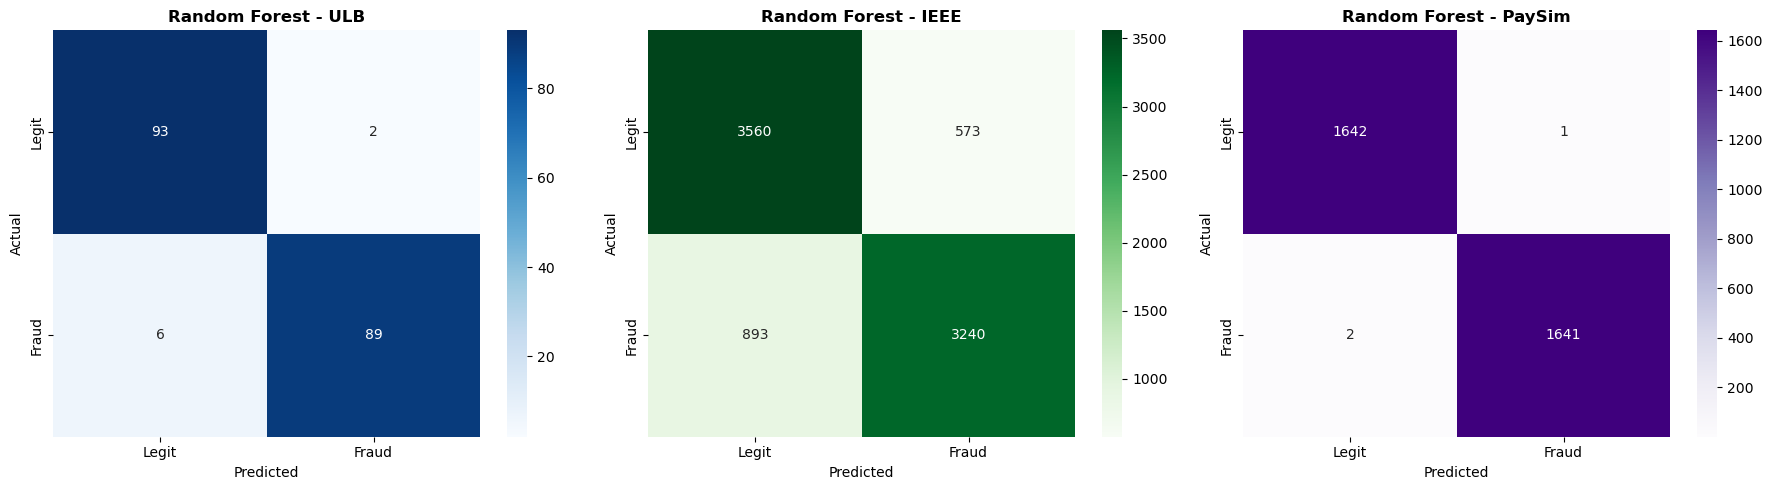

Saved: model3_confusion_matrices.png


In [7]:
# =============================================
# CONFUSION MATRICES (ALL 3 DATASETS)
# =============================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = ['Blues', 'Greens', 'Purples']

for idx, (name, color) in enumerate(zip(["ULB", "IEEE", "PaySim"], colors)):
    cm = results[name]['cm']
    sns.heatmap(cm, annot=True, fmt='d', cmap=color, ax=axes[idx],
                xticklabels=['Legit', 'Fraud'], yticklabels=['Legit', 'Fraud'])
    axes[idx].set_title(f'Random Forest - {name}', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Predicted')
    axes[idx].set_ylabel('Actual')

plt.tight_layout()
plt.savefig("../results/figures/model3_confusion_matrices.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: model3_confusion_matrices.png")

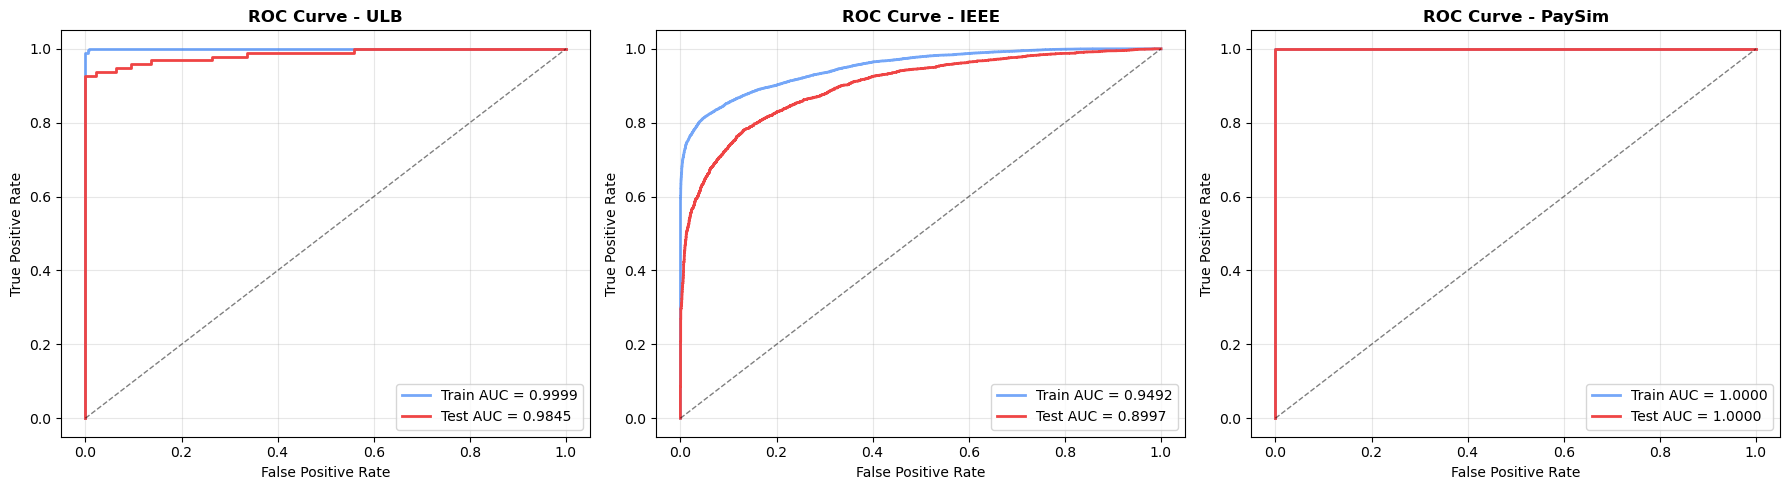

Saved: model3_roc_curves.png


In [8]:
# =============================================
# ROC CURVES: TRAIN vs TEST (ALL 3 DATASETS)
# =============================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, name in enumerate(["ULB", "IEEE", "PaySim"]):
    r = results[name]
    
    # Test ROC
    fpr_test, tpr_test, _ = roc_curve(r['y_test'], r['y_prob'])
    auc_test = auc(fpr_test, tpr_test)
    
    # Train ROC
    fpr_train, tpr_train, _ = roc_curve(r['y_train'], r['y_train_prob'])
    auc_train = auc(fpr_train, tpr_train)
    
    axes[idx].plot(fpr_train, tpr_train, color='#3b82f6', lw=2, 
                   label=f'Train AUC = {auc_train:.4f}', alpha=0.7)
    axes[idx].plot(fpr_test, tpr_test, color='#ef4444', lw=2, 
                   label=f'Test AUC = {auc_test:.4f}')
    axes[idx].plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.5)
    axes[idx].set_title(f'ROC Curve - {name}', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('False Positive Rate')
    axes[idx].set_ylabel('True Positive Rate')
    axes[idx].legend(loc='lower right')
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("../results/figures/model3_roc_curves.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: model3_roc_curves.png")

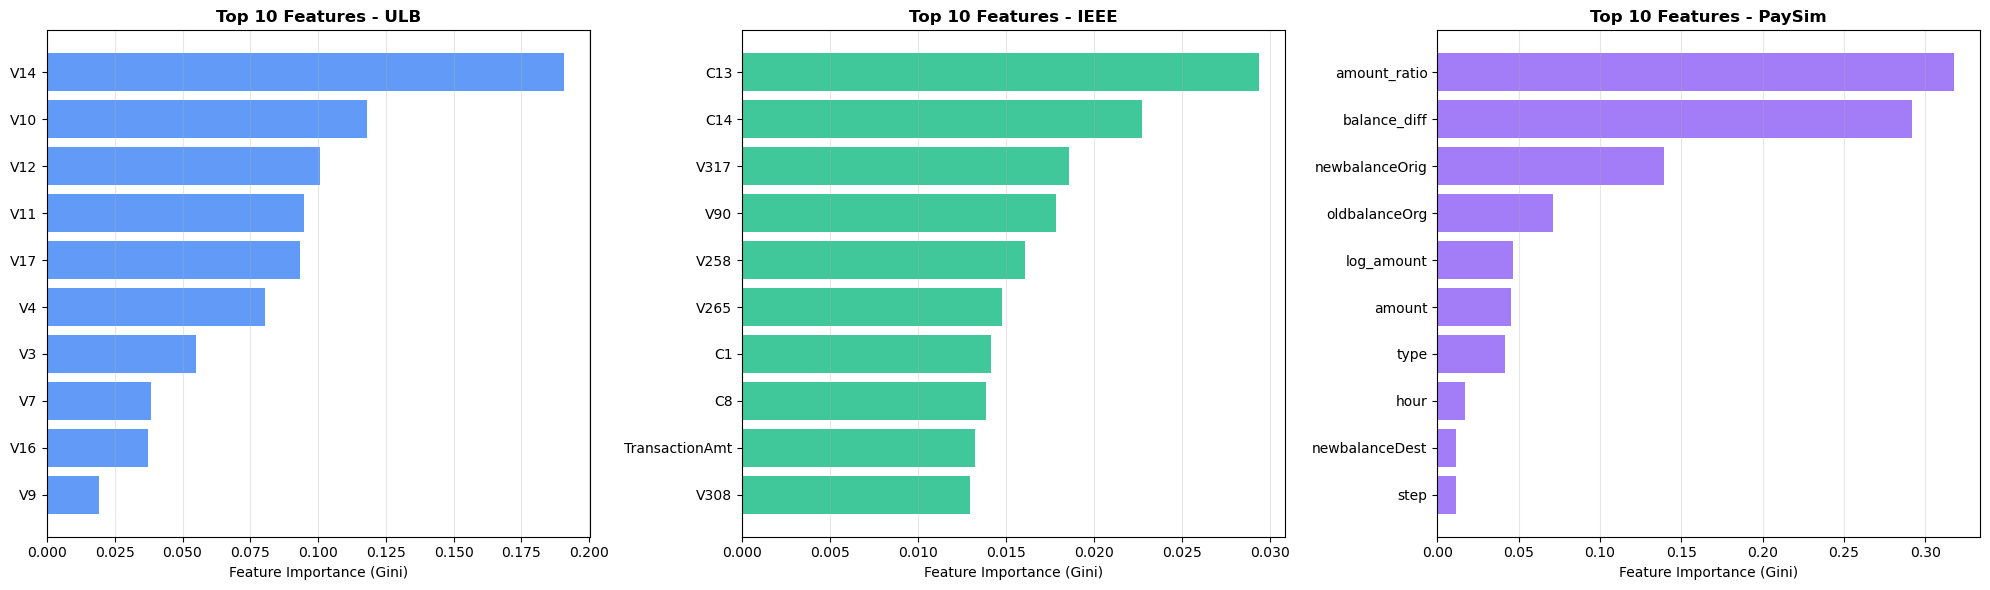

Saved: model3_feature_importance.png


In [9]:
# =============================================
# TOP 10 FEATURE IMPORTANCE (ALL 3 DATASETS)
# =============================================

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
colors_bar = ['#3b82f6', '#10b981', '#8b5cf6']

for idx, (name, color) in enumerate(zip(["ULB", "IEEE", "PaySim"], colors_bar)):
    imp_df = results[name]['importance_df'].head(10)
    
    axes[idx].barh(imp_df['Feature'], imp_df['Importance'], color=color, alpha=0.8)
    axes[idx].set_title(f'Top 10 Features - {name}', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Feature Importance (Gini)')
    axes[idx].invert_yaxis()
    axes[idx].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig("../results/figures/model3_feature_importance.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: model3_feature_importance.png")

In [10]:
# =============================================
# DETAILED CLASSIFICATION REPORTS
# =============================================

for name in ["ULB", "IEEE", "PaySim"]:
    print(f"\n{'='*50}")
    print(f"  Classification Report: {name}")
    print(f"{'='*50}")
    print(classification_report(results[name]['y_test'], results[name]['y_pred'], 
                                 target_names=['Legitimate', 'Fraud']))


  Classification Report: ULB
              precision    recall  f1-score   support

  Legitimate       0.94      0.98      0.96        95
       Fraud       0.98      0.94      0.96        95

    accuracy                           0.96       190
   macro avg       0.96      0.96      0.96       190
weighted avg       0.96      0.96      0.96       190


  Classification Report: IEEE
              precision    recall  f1-score   support

  Legitimate       0.80      0.86      0.83      4133
       Fraud       0.85      0.78      0.82      4133

    accuracy                           0.82      8266
   macro avg       0.82      0.82      0.82      8266
weighted avg       0.82      0.82      0.82      8266


  Classification Report: PaySim
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00      1643
       Fraud       1.00      1.00      1.00      1643

    accuracy                           1.00      3286
   macro avg       1.00      1.00 

In [11]:
# =============================================
# SAVE MODELS AND METRICS
# =============================================

all_dataset_metrics = {}

for name, config in DATASETS.items():
    r = results[name]
    
    # Save model artifact (per dataset)
    model_filename = f"random_forest_{name.lower()}.pkl"
    model_path = f"../results/models/{model_filename}"
    
    joblib.dump({
        'model': r['model'],
        'scaler': r['scaler'],
        'feature_names': r['feature_names'],
        'dataset': name,
        'target_column': config['target'],
        'dropped_columns': config['drop_cols']
    }, model_path)
    
    print(f"Saved model: {model_path}")
    
    # Build metrics dict
    tn, fp, fn, tp = r['cm'].ravel()
    
    # Top 10 feature importance for JSON
    top_features = r['importance_df'].head(10)
    total_imp = top_features['Importance'].sum()
    feature_importance_list = [
        {"name": row['Feature'], "value": round((row['Importance'] / total_imp) * 100, 2) if total_imp > 0 else 0}
        for _, row in top_features.iterrows()
    ]
    
    dataset_metrics = {
        "name": "Random Forest",
        "model_key": "random_forest",
        "dataset": name,
        "dataset_description": config["description"],
        "artifact": model_filename,
        "accuracy": r['metrics']['accuracy'],
        "precision": r['metrics']['precision'],
        "recall": r['metrics']['recall'],
        "f1_score": r['metrics']['f1_score'],
        "auc_roc": r['metrics']['auc_roc'],
        "confusion_matrix": {
            "true_negative": int(tn),
            "false_positive": int(fp),
            "false_negative": int(fn),
            "true_positive": int(tp)
        },
        "classification_report": r['report'],
        "split": {
            "dataset_path": config["path"],
            "total_samples": r['split_info']['total_samples'],
            "train_rows": r['split_info']['train_rows'],
            "test_rows": r['split_info']['test_rows'],
            "test_size": r['split_info']['test_size'],
            "random_state": r['split_info']['random_state'],
            "fraud_rate_train": r['split_info']['fraud_rate_train'],
            "fraud_rate_test": r['split_info']['fraud_rate_test'],
            "n_features": r['split_info']['n_features'],
            "dropped_columns": r['split_info']['dropped_columns']
        },
        "feature_importance": feature_importance_list,
        "supports_probability": True,
        "overfitting": {
            "train_accuracy": r['metrics']['train_accuracy'],
            "test_accuracy": r['metrics']['accuracy'],
            "train_auc": r['metrics']['train_auc'],
            "test_auc": r['metrics']['auc_roc']
        }
    }
    
    all_dataset_metrics[name] = dataset_metrics

# Save per-dataset metrics
for name, metrics in all_dataset_metrics.items():
    metrics_path = f"../results/metrics/model3_random_forest_{name.lower()}_metrics.json"
    with open(metrics_path, 'w') as f:
        json.dump(metrics, f, indent=2)
    print(f"Saved metrics: {metrics_path}")

# Save combined metrics (averaged across all datasets)
avg_metrics = {
    "name": "Random Forest",
    "model_key": "random_forest",
    "artifact": "model3_random_forest.pkl",
    "accuracy": float(np.mean([all_dataset_metrics[d]["accuracy"] for d in all_dataset_metrics])),
    "precision": float(np.mean([all_dataset_metrics[d]["precision"] for d in all_dataset_metrics])),
    "recall": float(np.mean([all_dataset_metrics[d]["recall"] for d in all_dataset_metrics])),
    "f1_score": float(np.mean([all_dataset_metrics[d]["f1_score"] for d in all_dataset_metrics])),
    "auc_roc": float(np.mean([all_dataset_metrics[d]["auc_roc"] for d in all_dataset_metrics])),
    "confusion_matrix": all_dataset_metrics["ULB"]["confusion_matrix"],
    "classification_report": all_dataset_metrics["ULB"]["classification_report"],
    "split": {
        "datasets_used": ["ULB", "IEEE", "PaySim"],
        "total_samples": sum(all_dataset_metrics[d]["split"]["total_samples"] for d in all_dataset_metrics),
        "train_rows": sum(all_dataset_metrics[d]["split"]["train_rows"] for d in all_dataset_metrics),
        "test_rows": sum(all_dataset_metrics[d]["split"]["test_rows"] for d in all_dataset_metrics),
        "test_size": 0.2,
        "random_state": 42
    },
    "per_dataset": {name: {
        "accuracy": m["accuracy"],
        "precision": m["precision"],
        "recall": m["recall"],
        "f1_score": m["f1_score"],
        "auc_roc": m["auc_roc"]
    } for name, m in all_dataset_metrics.items()},
    "feature_importance": all_dataset_metrics["ULB"]["feature_importance"],
    "supports_probability": True
}

with open("../results/metrics/model3_random_forest_metrics.json", 'w') as f:
    json.dump(avg_metrics, f, indent=2)
print("\nSaved combined metrics: model3_random_forest_metrics.json")

# Save the primary model (ULB as default for API compatibility)
joblib.dump({
    'model': results['ULB']['model'],
    'scaler': results['ULB']['scaler'],
    'feature_names': results['ULB']['feature_names'],
    'dataset': 'ULB',
    'target_column': 'Class',
    'dropped_columns': []
}, "../results/models/model3_random_forest.pkl")

print("\nAll models and metrics saved successfully!")

Saved model: ../results/models/random_forest_ulb.pkl
Saved model: ../results/models/random_forest_ieee.pkl
Saved model: ../results/models/random_forest_paysim.pkl
Saved metrics: ../results/metrics/model3_random_forest_ulb_metrics.json
Saved metrics: ../results/metrics/model3_random_forest_ieee_metrics.json
Saved metrics: ../results/metrics/model3_random_forest_paysim_metrics.json

Saved combined metrics: model3_random_forest_metrics.json

All models and metrics saved successfully!


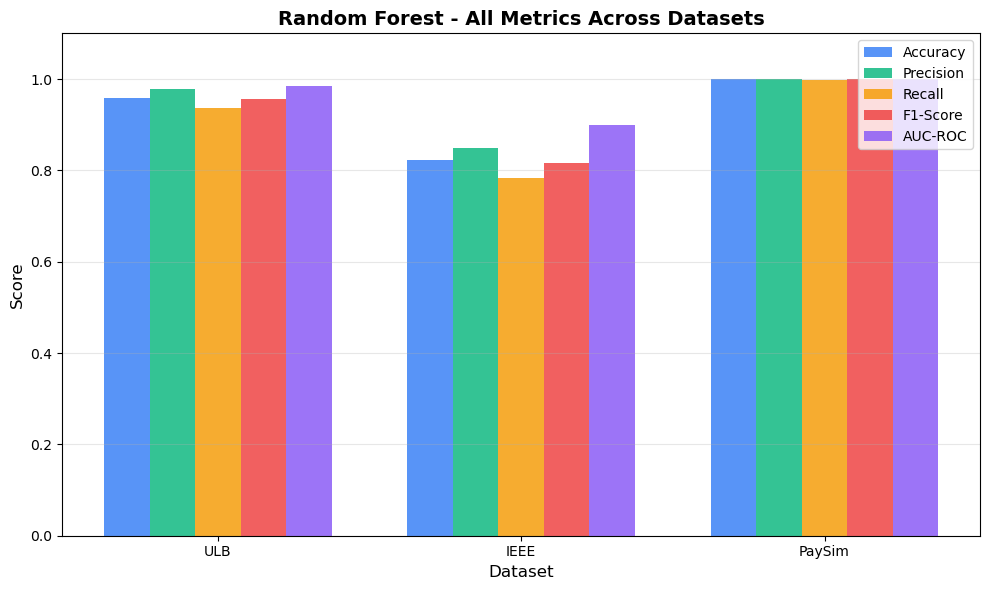

Saved: model3_dataset_comparison.png


In [12]:
# =============================================
# METRICS COMPARISON ACROSS DATASETS
# =============================================

fig, ax = plt.subplots(figsize=(10, 6))

datasets = ["ULB", "IEEE", "PaySim"]
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']
x = np.arange(len(datasets))
width = 0.15
colors = ['#3b82f6', '#10b981', '#f59e0b', '#ef4444', '#8b5cf6']

for i, metric_name in enumerate(metrics_names):
    key = metric_name.lower().replace('-', '_').replace(' ', '_')
    values = [results[d]['metrics'][key] for d in datasets]
    ax.bar(x + i * width, values, width, label=metric_name, color=colors[i], alpha=0.85)

ax.set_xlabel('Dataset', fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Random Forest - All Metrics Across Datasets', fontsize=14, fontweight='bold')
ax.set_xticks(x + width * 2)
ax.set_xticklabels(datasets)
ax.set_ylim(0, 1.1)
ax.legend(loc='upper right')
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig("../results/figures/model3_dataset_comparison.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: model3_dataset_comparison.png")

In [13]:
# =============================================
# FINAL SUMMARY
# =============================================

print("="*70)
print("  RANDOM FOREST - FINAL TRAINING SUMMARY")
print("="*70)
print()

for name in ["ULB", "IEEE", "PaySim"]:
    m = results[name]['metrics']
    s = results[name]['split_info']
    print(f"  {name} ({DATASETS[name]['description']})")
    print(f"    Samples: {s['total_samples']:,} | Features: {s['n_features']}")
    print(f"    Dropped cols: {s['dropped_columns'] if s['dropped_columns'] else 'None'}")
    print(f"    Accuracy={m['accuracy']:.4f}  Precision={m['precision']:.4f}  "
          f"Recall={m['recall']:.4f}  F1={m['f1_score']:.4f}  AUC={m['auc_roc']:.4f}")
    print(f"    Overfit: Train Acc={m['train_accuracy']:.4f} vs Test Acc={m['accuracy']:.4f} "
          f"(gap={m['train_accuracy']-m['accuracy']:.4f})")
    print()

print("  Models saved to: ../results/models/")
print("  Metrics saved to: ../results/metrics/")
print("  Figures saved to: ../results/figures/")
print("="*70)

  RANDOM FOREST - FINAL TRAINING SUMMARY

  ULB (ULB Credit Card Fraud Dataset)
    Samples: 946 | Features: 32
    Dropped cols: None
    Accuracy=0.9579  Precision=0.9780  Recall=0.9368  F1=0.9570  AUC=0.9845
    Overfit: Train Acc=0.9921 vs Test Acc=0.9579 (gap=0.0342)

  IEEE (IEEE-CIS Fraud Detection Dataset)
    Samples: 41,326 | Features: 433
    Dropped cols: ['TransactionID', 'V305']
    Accuracy=0.8226  Precision=0.8497  Recall=0.7839  F1=0.8155  AUC=0.8997
    Overfit: Train Acc=0.8817 vs Test Acc=0.8226 (gap=0.0590)

  PaySim (PaySim Mobile Money Fraud Dataset)
    Samples: 16,426 | Features: 11
    Dropped cols: ['isFlaggedFraud']
    Accuracy=0.9991  Precision=0.9994  Recall=0.9988  F1=0.9991  AUC=1.0000
    Overfit: Train Acc=0.9989 vs Test Acc=0.9991 (gap=-0.0002)

  Models saved to: ../results/models/
  Metrics saved to: ../results/metrics/
  Figures saved to: ../results/figures/
